In [1]:
# conda vis2
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import at3d

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-paper')

In [2]:
import src.Retrieval as retrieval


In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'CVM' / 'unconstrained'

r = retrieval.Retrieval(EXPERIMENT)
r.load_retrieval()

tmp_ext = r.solvers_retrieval[0.67].medium['cloud'].extinction.data
tmp_ext[:,:,-1] = 0
r.solvers_retrieval[0.67].medium['cloud']['extinction'] = (['x','y','z'], tmp_ext)

sensor_dict = r.sensors_retrieval.make_forward_sensors()
sensor_dict.get_measurements(r.solvers_retrieval, n_jobs=4, verbose=True)

at3d.util.save_forward_model(
    str(PROJECT_ROOT / 'experiments' / 'tmp' / 'V08_unc_mod.nc'),
    sensor_dict,
    r.solvers_retrieval
)

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.855  0.408E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     2  -1.453  0.414E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     3  -1.942  0.415E+00    63375   256.00  1.000   [Radiance 0.670 micron]
     4  -2.118  0.193E+00    64714   256.00  1.000   [Radiance 0.670 micron]
     5  -2.133  0.108E+00    70856   256.00  1.000   [Radiance 0.670 micron]
     6  -2.253  0.796E-01    78585   256.00  1.000   [Radiance 0.670 micron]
     7  -2.346  0.616E-01    89688   256.00  1.000   [Radiance 0.670 micron]
     8  -2.400  0.501E-01   102340   256.00  1.000   [Radiance 0.670 micron]
     9  -2.435  0.431E-01   115025   256.00  1.000   [Radiance 0.670 micron]
    10  -2.168  0.388E-01   126390   256.00  1.000   [Radiance 0.670 micron]
    11  -2.308  0.388E-01   126877   256.00  1.000   [Radiance 0.670 micron]
    12  -2.708  0.388E-01   127103   256.00  1.000   [Radiance 0.670 micron]
  

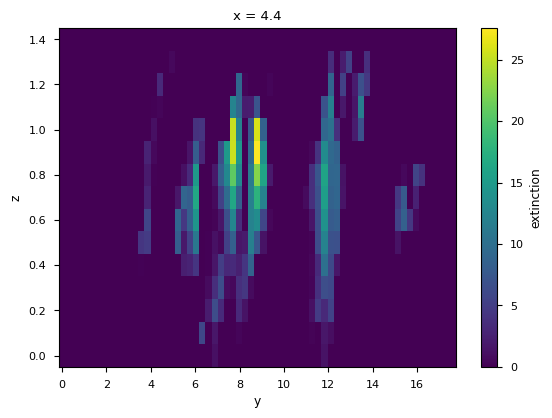

In [7]:
r.solvers_retrieval[0.67].medium['cloud']['extinction'].isel(x=16).plot(y='z')